<a href="https://colab.research.google.com/github/sairiamu/ML-DL-collection/blob/main/HTML_to_MP4_Reel_Studio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🎬 HTML → MP4 Reel Studio

A reusable pipeline that turns **any HTML / CSS / SVG / JS animation** into a **high‑resolution MP4** for Instagram & Facebook Reels, Shorts, TikTok, feed posts and explainers.

**What it does**

| Step | What happens |
|---|---|
| Render | Headless Chromium captures every frame on a **virtual clock** (CSS animations, SVG, `setTimeout`, `requestAnimationFrame`, Web Animations all advance exactly one frame per screenshot → perfectly smooth, never drops frames) |
| Resolution | Layout stays identical while pixels scale (`1×` = 1080p, `2×` = 4K, `3×` = 6K) |
| Sound | AI narration with **per‑line timing** (edge‑tts, free), your own narration, background music with **auto‑ducking**, sound effects at exact timestamps, loudness normalised to −14 LUFS |
| Captions | Burned‑in big captions (or `.srt` only) generated from your narration script |
| Export | H.264/AAC MP4 (`yuv420p`, BT.709, `faststart`), optional 1080p copy for IG/FB, cover image, captions file, one‑click download or Drive save |

**Quick start:** `Runtime → Run all`. Run the first time with `SOURCE = "demo"` to check everything works, then switch to `upload`.

**The 8 steps:** 1 Install · 2 Settings · 3 Content (script / SFX) · 4 Load HTML · 5 Renderer · 6 Sound · 7 Preview · 8 Render · 9 Encode · 10 Check · 11 Download

In [1]:
#@title 1 · Install everything (≈2 min on first run) { display-mode: "form" }
import subprocess, sys, shutil

def sh(cmd):
    r = subprocess.run(cmd, shell=True, text=True, capture_output=True)
    if r.returncode != 0:
        print(r.stdout[-2500:], r.stderr[-2500:])
        raise RuntimeError("command failed: " + cmd)
    return r.stdout

print("• Python packages…")
sh(f"{sys.executable} -m pip install -q --upgrade playwright edge-tts pillow")
print("• Chromium + system libraries…")
sh(f"{sys.executable} -m playwright install --with-deps chromium")
print("• Fonts…")
subprocess.run("apt-get -qq install -y fonts-noto-core fonts-noto-color-emoji fonts-liberation fonts-dejavu-core fonts-roboto > /dev/null 2>&1", shell=True)
subprocess.run("fc-cache -f > /dev/null 2>&1", shell=True)
if not shutil.which("ffmpeg"):
    print("• ffmpeg…")
    sh("apt-get -qq install -y ffmpeg")

feat = sh("ffmpeg -hide_banner -encoders; ffmpeg -hide_banner -filters")
need = {"libx264": "H.264 encoder", "libx265": "H.265 encoder", " subtitles ": "burned-in captions",
        "sidechaincompress": "music ducking", "loudnorm": "loudness normalisation"}
print()
for k, v in need.items():
    print(("✔" if k in feat else "✘"), v)
print("\nReady ✅")

• Python packages…
• Chromium + system libraries…
• Fonts…

✔ H.264 encoder
✔ H.265 encoder
✔ burned-in captions
✔ music ducking
✔ loudness normalisation

Ready ✅


In [2]:
#@title 2 · Settings { display-mode: "form" }
import os, re, json, math, glob, shutil, subprocess, sys, time, hashlib, textwrap

#@markdown ### 📁 Project & source
PROJECT_NAME = "my_explainer"  #@param {type:"string"}
SOURCE = "upload"  #@param ["upload","paste","drive","url","demo"]
SOURCE_URL = ""  #@param {type:"string"}
DRIVE_HTML_PATH = "/content/drive/MyDrive/my_explainer/index.html"  #@param {type:"string"}
MAIN_HTML = ""  #@param {type:"string"}
REUPLOAD = False  #@param {type:"boolean"}

#@markdown ### 📐 Format & resolution  (layout size × scale = output pixels)
PRESET = "Reel / Short / TikTok 9:16 · 1080x1920"  #@param ["Reel / Short / TikTok 9:16 · 1080x1920","Feed portrait 4:5 · 1080x1350","Square 1:1 · 1080x1080","Landscape 16:9 · 1920x1080","Custom"]
CUSTOM_W = 1080  #@param {type:"integer"}
CUSTOM_H = 1920  #@param {type:"integer"}
OUTPUT_SCALE = 2  #@param [1, 1.5, 2, 3] {type:"raw"}
FPS = 30  #@param [24, 25, 30, 50, 60] {type:"raw"}
BG_COLOR = "#000000"  #@param {type:"string"}

#@markdown ### ⏱ Timing
DURATION_MODE = "manual"  #@param ["manual","match_audio"]
DURATION_S = 64  #@param {type:"number"}
START_S = 0  #@param {type:"number"}
MATCH_AUDIO_TAIL_S = 1.5  #@param {type:"number"}

#@markdown ### 🎯 Capture
CAPTURE_SELECTOR = ""  #@param {type:"string"}
INJECT_CSS = ""  #@param {type:"string"}
INJECT_JS = ""  #@param {type:"string"}
TIME_MODE = "auto"  #@param ["auto","virtual","seek"]
FRAME_FORMAT = "png"  #@param ["png","jpeg"]
JPEG_QUALITY = 95  #@param {type:"slider", min:80, max:100, step:1}
WORKERS = 2  #@param {type:"slider", min:1, max:8, step:1}
SETTLE_MS = 10  #@param {type:"integer"}
RESUME = True  #@param {type:"boolean"}

#@markdown ### 🎞 Encoding
CODEC = "h264"  #@param ["h264","h265"]
CRF = 17  #@param {type:"slider", min:12, max:28, step:1}
ENCODE_PRESET = "slow"  #@param ["medium","slow","slower"]
ALSO_EXPORT_1080 = True  #@param {type:"boolean"}
COVER_TIME_S = 1.0  #@param {type:"number"}

#@markdown ### 🔊 Sound
NARRATION_SOURCE = "tts"  #@param ["tts","upload","none"]
TTS_VOICE = "en-US-AriaNeural"  #@param ["en-US-AriaNeural","en-US-GuyNeural","en-US-JennyNeural","en-US-AndrewNeural","en-US-EmmaNeural","en-GB-SoniaNeural","en-GB-RyanNeural","en-AU-NatashaNeural","en-IN-NeerjaNeural","sw-TZ-RehemaNeural","sw-TZ-DaudiNeural","fr-FR-DeniseNeural","es-ES-ElviraNeural","de-DE-KatjaNeural","ar-EG-SalmaNeural"] {allow-input: true}
TTS_RATE = "+0%"  #@param {type:"string"}
NARRATION_GAP_S = 0.5  #@param {type:"number"}
NARRATION_VOLUME_DB = 0  #@param {type:"number"}
MUSIC_SOURCE = "none"  #@param ["none","upload"]
MUSIC_VOLUME_DB = -20  #@param {type:"number"}
DUCK_MUSIC = True  #@param {type:"boolean"}
MUSIC_FADE_IN_S = 1.5  #@param {type:"number"}
MUSIC_FADE_OUT_S = 2.5  #@param {type:"number"}
NORMALIZE_LOUDNESS = True  #@param {type:"boolean"}
TARGET_LUFS = -14  #@param {type:"number"}
SILENT_TRACK_IF_NO_AUDIO = True  #@param {type:"boolean"}

#@markdown ### 💬 Captions
CAPTIONS = "burn_in"  #@param ["burn_in","srt_only","off"]
CAPTION_FONT = "DejaVu Sans"  #@param ["DejaVu Sans","Noto Sans","Roboto","Liberation Sans"] {allow-input: true}
CAPTION_FONT_SIZE = 64  #@param {type:"integer"}
CAPTION_WORDS_PER_CHUNK = 6  #@param {type:"integer"}
CAPTION_BOTTOM_MARGIN = 260  #@param {type:"integer"}

#@markdown ### 💾 Output
SAVE_TO_DRIVE = False  #@param {type:"boolean"}
DRIVE_FOLDER = "ReelRenders"  #@param {type:"string"}
CLEANUP_FRAMES = True  #@param {type:"boolean"}

# ------------------------------------------------------------------ derived
PRESETS = {
    "Reel / Short / TikTok 9:16 · 1080x1920": (1080, 1920),
    "Feed portrait 4:5 · 1080x1350": (1080, 1350),
    "Square 1:1 · 1080x1080": (1080, 1080),
    "Landscape 16:9 · 1920x1080": (1920, 1080),
    "Custom": None,
}
LW, LH = PRESETS[PRESET] or (int(CUSTOM_W), int(CUSTOM_H))
OW = int(round(LW * float(OUTPUT_SCALE) / 2) * 2)
OH = int(round(LH * float(OUTPUT_SCALE) / 2) * 2)
SLUG = re.sub(r"[^A-Za-z0-9_-]+", "_", PROJECT_NAME).strip("_") or "project"
BASE = "/content" if os.path.isdir("/content") else os.path.abspath("./colab_content")
WORK = f"{BASE}/reel_work/{SLUG}"
FRAMES, PREVIEW, OUT = f"{WORK}/frames", f"{WORK}/preview", f"{BASE}/reel_out/{SLUG}"
CFG_PATH = f"{WORK}/config.json"
for d in (WORK, OUT):
    os.makedirs(d, exist_ok=True)
PAGE_URL = None

# ------------------------------------------------------------------ helpers
def stream(cmd, cwd=None):
    """Run a command and print its output live."""
    p = subprocess.Popen(cmd, cwd=cwd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    for line in p.stdout:
        print(line, end="")
    p.wait()
    if p.returncode:
        raise RuntimeError(f"command failed ({p.returncode}): {' '.join(map(str, cmd))[:200]}")

def probe_duration(path):
    r = subprocess.run(["ffprobe", "-v", "error", "-show_entries", "format=duration", "-of", "default=nw=1:nk=1", path],
                       capture_output=True, text=True)
    return float(r.stdout.strip())

def ask_upload(prompt, dest):
    os.makedirs(dest, exist_ok=True)
    try:
        from google.colab import files
    except ImportError:
        raise SystemExit(f"{prompt}\nNot running in Colab: copy the file(s) into {dest} manually and re-run.")
    print("⬆ " + prompt)
    saved = []
    for name, data in files.upload().items():
        p = os.path.join(dest, os.path.basename(name))
        with open(p, "wb") as f:
            f.write(data)
        saved.append(p)
    return saved

def write_cfg(**over):
    cfg = dict(url=PAGE_URL, vw=LW, vh=LH, dsf=float(OUTPUT_SCALE), fps=int(FPS), duration_s=float(DURATION_S),
               start_s=float(START_S), time_mode=TIME_MODE, selector=CAPTURE_SELECTOR.strip(),
               inject_css=INJECT_CSS, inject_js=INJECT_JS, frame_format=FRAME_FORMAT,
               jpeg_quality=int(JPEG_QUALITY), workers=int(WORKERS), resume=bool(RESUME),
               settle_ms=int(SETTLE_MS), frames_dir=FRAMES, preview_dir=PREVIEW)
    cfg.update(over)
    with open(CFG_PATH, "w") as f:
        json.dump(cfg, f, indent=1)
    return cfg

def mmss(s):
    s = int(round(s))
    return f"{s // 60}:{s % 60:02d}"

print(f"Layout {LW}×{LH}  ×{OUTPUT_SCALE}  →  output {OW}×{OH} @ {FPS} fps, {DURATION_S}s  ({int(DURATION_S * FPS)} frames)")
print(f"Working folder: {WORK}")

Layout 1080×1920  ×2  →  output 2160×3840 @ 30 fps, 64s  (1920 frames)
Working folder: /content/reel_work/my_explainer


In [3]:
#@title 3 · Content: narration script, sound effects, optional pasted HTML { display-mode: "form" }

# --- Narration script -------------------------------------------------------
# One line per sentence/scene.  Format:   start_seconds | text      (or  m:ss | text)
# Lines WITHOUT a start time simply follow the previous line (+ NARRATION_GAP_S).
# Times are measured from the START OF THE VIDEO.  Lines starting with # are ignored.
# This example matches the 6 scenes of the recordanelle explainer; replace it with yours.
NARRATION_SCRIPT = """
0  | Most tools only give a snapshot of gene activity, so a short burst of expression can vanish before you measure it.
9  | The recordanelle is one engineered protein. It anchors to mitochondria, builds a small condensate, and grabs messenger RNAs by their poly-A tails.
20 | When genes switch on, their RNAs are pulled into the condensate and protected, while free RNAs in the cytoplasm decay.
31 | Up to ninety percent of expressed genes are represented, and after an interferon pulse, every response gene was still detectable two days later.
42 | In single cells, only those carrying recordanelle version two still show the interferon response cluster after two days.
53 | Limits remain: cell division dilutes the record, and any recorder is itself a perturbation. Source: Nature Biotechnology, twenty twenty-six.
"""

# --- Sound effects ----------------------------------------------------------
# (file name, start second in the video, volume in dB).  You will be asked to upload the files.
SFX = [
    # ("whoosh.mp3", 9.0, -8),
    # ("pop.wav",   20.0, -10),
]

# --- Pasted HTML (only used when SOURCE = "paste") --------------------------
HTML_TEXT = r"""
<!-- paste your complete HTML document here -->
"""
print("Narration lines:", len([l for l in NARRATION_SCRIPT.strip().splitlines() if l.strip() and not l.strip().startswith('#')]), "| SFX:", len(SFX))

Narration lines: 6 | SFX: 0


In [4]:
#@title 4 · Load the HTML animation { display-mode: "form" }
import zipfile, pathlib

DEMO_HTML = """<!doctype html><html><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1">
<style>
html,body{margin:0;height:100%;background:#0f1226;color:#fff;font-family:system-ui,sans-serif;overflow:hidden}
.wrap{height:100%;display:flex;flex-direction:column;align-items:center;justify-content:center;gap:5vh}
h1{font-size:9vw;margin:0;opacity:0;animation:in 1s ease .3s forwards}
.orb{width:30vw;height:30vw;border-radius:50%;background:radial-gradient(circle at 30% 30%,#ff9ad5,#6a5cff);animation:float 3s ease-in-out infinite}
#t{font-size:5vw;opacity:.85}
canvas{width:80vw;height:6vw;border-radius:3vw;background:#ffffff22}
@keyframes in{from{opacity:0;transform:translateY(6vh)}to{opacity:1;transform:none}}
@keyframes float{50%{transform:translateY(-6vh) scale(1.08)}}
</style></head><body><div class="wrap"><h1>Pipeline OK</h1><div class="orb"></div><div id="t">0 s</div><canvas id="c" width="800" height="60"></canvas></div>
<script>
let s=0;setInterval(()=>{s++;document.getElementById("t").textContent=s+" s (setInterval)"},1000);
const c=document.getElementById("c").getContext("2d");
function f(ts){c.clearRect(0,0,800,60);c.fillStyle="#ff9ad5";c.fillRect(0,0,Math.min(800,ts/10000*800),60);requestAnimationFrame(f)}
requestAnimationFrame(f);
</script></body></html>"""

PROJ = f"{WORK}/site"
os.makedirs(PROJ, exist_ok=True)

def fresh_site():
    shutil.rmtree(PROJ, ignore_errors=True)
    os.makedirs(PROJ, exist_ok=True)

def find_main():
    if MAIN_HTML.strip():
        p = os.path.join(PROJ, MAIN_HTML.strip())
        if os.path.exists(p):
            return p
        raise SystemExit(f"MAIN_HTML '{MAIN_HTML}' not found in {PROJ}")
    c = glob.glob(PROJ + "/**/index.html", recursive=True) or glob.glob(PROJ + "/**/*.html", recursive=True)
    if not c:
        raise SystemExit("No .html file found. Upload one, or choose SOURCE = 'demo' to test the pipeline.")
    c.sort(key=lambda p: (p.count(os.sep), p))
    if len(c) > 1:
        print("Several HTML files found, using the first. Set MAIN_HTML to choose:", [os.path.relpath(x, PROJ) for x in c])
    return c[0]

if SOURCE == "url":
    if not SOURCE_URL.startswith("http"):
        raise SystemExit("SOURCE_URL must start with http(s)://")
    PAGE_URL = SOURCE_URL
    print("Using remote page:", PAGE_URL)
else:
    if SOURCE == "upload":
        have = glob.glob(PROJ + "/**/*.html", recursive=True)
        if REUPLOAD or not have:
            fresh_site()
            for p in ask_upload("Choose your .html file (plus any assets, or one .zip with everything)", PROJ):
                if p.endswith(".zip"):
                    zipfile.ZipFile(p).extractall(PROJ)
        else:
            print("Reusing previously uploaded site (tick REUPLOAD to replace it).")
    elif SOURCE == "paste":
        if "<" not in HTML_TEXT.replace("<!-- paste your complete HTML document here -->", ""):
            raise SystemExit("Paste your HTML into HTML_TEXT in cell 3 first.")
        fresh_site()
        open(os.path.join(PROJ, "index.html"), "w", encoding="utf-8").write(HTML_TEXT)
    elif SOURCE == "drive":
        from google.colab import drive
        drive.mount("/content/drive")
        src = DRIVE_HTML_PATH
        if not os.path.exists(src):
            raise SystemExit("File not found on Drive: " + src)
        fresh_site()
        parent = os.path.dirname(src)
        size = sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(parent) for f in fs)
        if size < 200e6:
            shutil.copytree(parent, PROJ, dirs_exist_ok=True)
            MAIN_HTML = os.path.basename(src)
        else:
            shutil.copy(src, PROJ)
            print("Folder > 200 MB: copied only the HTML file (assets must be inline).")
    elif SOURCE == "demo":
        fresh_site()
        open(os.path.join(PROJ, "index.html"), "w", encoding="utf-8").write(DEMO_HTML)
    main_html = find_main()
    PAGE_URL = pathlib.Path(main_html).resolve().as_uri()
    txt = open(main_html, encoding="utf-8", errors="ignore").read()
    print(f"Loaded {os.path.relpath(main_html, PROJ)}  ({len(txt) / 1024:.0f} KB)")
    notes = []
    if "window.seek" in txt: notes.append("defines window.seek(ms) → will be used for exact timing")
    if re.search(r"<video|<audio", txt): notes.append("⚠ contains <video>/<audio>: media elements are NOT frame-accurate; add sound in step 6 instead")
    if re.search(r"""(src|href)=["']https?://""", txt): notes.append("uses external files (CDN/fonts): fine in Colab, but pin versions for reproducibility")
    if re.search(r"Math\.random", txt): notes.append("⚠ uses Math.random(): results differ per run unless you seed it")
    for n in notes: print("  •", n)

print("PAGE_URL =", PAGE_URL)

⬆ Choose your .html file (plus any assets, or one .zip with everything)


Saving Recordanelles explained.html to Recordanelles explained.html
Loaded Recordanelles explained.html  (16 KB)
PAGE_URL = file:///content/reel_work/my_explainer/site/Recordanelles%20explained.html


### 5 · Renderer
Writes `render.py` (virtual clock + parallel Playwright workers). You normally never need to edit it.

In [5]:
%%writefile render.py
#!/usr/bin/env python3
"""
HTML -> frames renderer (virtual clock + parallel Playwright workers).

Usage:
    python render.py CONFIG.json                    # render every frame
    python render.py CONFIG.json --preview 0,5.5    # screenshot a few moments (seconds)

Every frame is captured on a *virtual clock*: Date, performance.now, setTimeout,
setInterval, requestAnimationFrame, CSS/Web animations and SVG SMIL all advance exactly
one frame per screenshot, so the result is perfectly smooth no matter how slow the
machine is.  If the page defines window.seek(ms) it is used instead (TIME_MODE auto/seek).
"""
import asyncio
import json
import os
import sys
import time

from playwright.async_api import async_playwright

VIRTUAL_CLOCK_JS = r"""
(() => {
  if (window.__vc) return;
  const BASE = (typeof window.__VC_BASE === 'number') ? window.__VC_BASE : 1700000000000;
  const NativeDate = Date;
  const state = { now: 0, seq: 1, ord: 1, timers: new Map(), raf: new Map(), rafSeq: 1,
                  born: new WeakMap(), svgBorn: new WeakMap(), zeroAt: -1, zeroCount: 0 };

  // ---- macrotask yield: lets promise continuations run between timer callbacks
  const ch = new MessageChannel();
  let waiters = [];
  ch.port1.onmessage = () => { const w = waiters; waiters = []; w.forEach(f => f()); };
  const yieldTask = () => new Promise(r => { waiters.push(r); ch.port2.postMessage(0); });

  // ---- Date / performance
  function VDate(...args) {
    if (!new.target) return new NativeDate(BASE + state.now).toString();
    if (args.length === 0) return new NativeDate(BASE + state.now);
    return new NativeDate(...args);
  }
  VDate.prototype = NativeDate.prototype;
  VDate.now = () => BASE + state.now;
  VDate.parse = NativeDate.parse;
  VDate.UTC = NativeDate.UTC;
  Object.setPrototypeOf(VDate, NativeDate);
  window.Date = VDate;
  try { Object.defineProperty(performance, 'now', { value: () => state.now, configurable: true, writable: true }); } catch (e) {}
  try { Object.defineProperty(document.timeline, 'currentTime', { get: () => state.now, configurable: true }); } catch (e) {}

  // ---- timers
  function addTimer(fn, delay, args, repeat) {
    if (typeof fn === 'string') { const src = fn; fn = () => (0, eval)(src); }
    if (typeof fn !== 'function') return 0;
    delay = Number(delay); if (!(delay >= 0)) delay = 0;
    if (repeat && delay < 1) delay = 1;
    if (delay < 1) {                       // guard against zero-delay chains that never advance time
      if (state.zeroAt === state.now) { if (++state.zeroCount > 50) delay = 1; }
      else { state.zeroAt = state.now; state.zeroCount = 0; }
    }
    const id = state.seq++;
    state.timers.set(id, { id, fn, args, due: state.now + delay, repeat: repeat ? delay : 0, ord: state.ord++ });
    return id;
  }
  window.setTimeout = (fn, d, ...a) => addTimer(fn, d, a, false);
  window.setInterval = (fn, d, ...a) => addTimer(fn, d, a, true);
  window.clearTimeout = window.clearInterval = (id) => { state.timers.delete(id); };
  window.requestAnimationFrame = (cb) => { const id = state.rafSeq++; state.raf.set(id, cb); return id; };
  window.cancelAnimationFrame = (id) => { state.raf.delete(id); };
  window.requestIdleCallback = (cb) => addTimer(() => cb({ didTimeout: true, timeRemaining: () => 50 }), 1, [], false);
  window.cancelIdleCallback = (id) => { state.timers.delete(id); };

  // ---- freeze CSS animations from the very first moment (we drive them ourselves)
  const css = '*,*::before,*::after{animation-play-state:paused !important}';
  function addStyle() {
    if (document.getElementById('__vc_style')) return true;
    const root = document.head || document.documentElement;
    if (!root) return false;
    const s = document.createElement('style'); s.id = '__vc_style'; s.textContent = css; root.appendChild(s);
    return true;
  }
  if (!addStyle()) {
    const mo = new MutationObserver(() => { if (addStyle()) mo.disconnect(); });
    mo.observe(document, { childList: true, subtree: true });
  }

  function syncAnimations(t, prevT) {
    let anims = [];
    try { anims = document.getAnimations(); } catch (e) {}
    for (const a of anims) {
      let b = state.born.get(a);
      if (b === undefined) { b = prevT; state.born.set(a, b); }
      try { a.pause(); a.currentTime = Math.max(0, t - b); } catch (e) {}
    }
    try {
      for (const s of document.querySelectorAll('svg')) {
        if (s.ownerSVGElement) continue;                 // outermost <svg> only
        let b = state.svgBorn.get(s);
        if (b === undefined) { b = prevT; state.svgBorn.set(s, b); }
        if (typeof s.pauseAnimations === 'function') { s.pauseAnimations(); s.setCurrentTime(Math.max(0, t - b) / 1000); }
      }
    } catch (e) {}
  }

  async function stepTo(t) {
    const prevT = state.now;
    let guard = 0;
    for (;;) {
      let best = null;
      for (const tm of state.timers.values()) {
        if (tm.due <= t && (!best || tm.due < best.due || (tm.due === best.due && tm.ord < best.ord))) best = tm;
      }
      if (!best) break;
      if (best.due > state.now) state.now = best.due;
      if (best.repeat) { best.due += best.repeat; best.ord = state.ord++; } else state.timers.delete(best.id);
      try { best.fn(...best.args); } catch (e) { console.error(e && e.stack || e); }
      await yieldTask();
      if (++guard > 200000) { console.error('virtual clock: too many timer callbacks in one step'); break; }
    }
    if (t > state.now) state.now = t;
    const cbs = Array.from(state.raf.values()); state.raf.clear();
    for (const cb of cbs) { try { cb(state.now); } catch (e) { console.error(e && e.stack || e); } }
    if (cbs.length) await yieldTask();
    syncAnimations(state.now, prevT);
  }

  async function advance(target, step) {
    step = step > 0 ? step : 1000 / 30;
    while (state.now + 1e-6 < target) await stepTo(Math.min(state.now + step, target));
    return state.now;
  }

  window.__vc = { state, stepTo, advance };
})();
"""

_log_counts = {"console": 0, "failed": 0}


def log(msg):
    print("[render] " + msg, flush=True)


def fmt_time(sec):
    sec = int(max(0, round(sec)))
    return f"{sec // 60}:{sec % 60:02d}"


def attach_logging(page):
    """Surface page problems (missing files, JS errors) so blank frames are easy to diagnose."""
    def on_console(m):
        if m.type == "error" and _log_counts["console"] < 6:
            _log_counts["console"] += 1
            log(f"page console error: {m.text[:200]}")

    def on_pageerror(e):
        if _log_counts["console"] < 6:
            _log_counts["console"] += 1
            log(f"page JS error: {str(e)[:200]}")

    def on_failed(r):
        if _log_counts["failed"] < 8 and "ERR_ABORTED" not in str(r.failure):
            _log_counts["failed"] += 1
            log(f"could not load: {r.url[:160]} ({r.failure})")

    page.on("console", on_console)
    page.on("pageerror", on_pageerror)
    page.on("requestfailed", on_failed)


def launch_args():
    return ["--no-sandbox", "--disable-dev-shm-usage", "--hide-scrollbars", "--force-color-profile=srgb",
            "--allow-file-access-from-files", "--autoplay-policy=no-user-gesture-required",
            "--disable-background-timer-throttling", "--disable-renderer-backgrounding",
            "--disable-backgrounding-occluded-windows"]


async def new_page(browser, cfg, virtual, base_epoch, log_events=False):
    ctx = await browser.new_context(viewport={"width": int(cfg["vw"]), "height": int(cfg["vh"])},
                                    device_scale_factor=float(cfg["dsf"]),
                                    bypass_csp=True, ignore_https_errors=True)
    if virtual:
        await ctx.add_init_script(f"window.__VC_BASE = {int(base_epoch)};\n" + VIRTUAL_CLOCK_JS)
    page = await ctx.new_page()
    if log_events:
        attach_logging(page)
    await page.goto(cfg["url"], wait_until="load", timeout=120_000)
    try:
        await page.wait_for_load_state("networkidle", timeout=8_000)
    except Exception:
        pass
    try:
        await page.evaluate("document.fonts ? document.fonts.ready.then(() => true) : true")
        await page.evaluate("Promise.all(Array.from(document.images).map(i => i.decode ? i.decode().catch(() => {}) : null))")
    except Exception:
        pass
    if cfg.get("inject_css"):
        await page.add_style_tag(content=cfg["inject_css"])
    if cfg.get("inject_js"):
        await page.add_script_tag(content=cfg["inject_js"])
    return page


async def detect_mode(browser, cfg):
    """Decide between the virtual clock and the page's own window.seek(ms)."""
    want = cfg.get("time_mode", "auto")
    if want == "virtual":
        return "virtual"
    ctx = await browser.new_context(viewport={"width": int(cfg["vw"]), "height": int(cfg["vh"])},
                                    bypass_csp=True, ignore_https_errors=True)
    page = await ctx.new_page()
    attach_logging(page)
    try:
        await page.goto(cfg["url"], wait_until="load", timeout=120_000)
        await page.wait_for_timeout(300)
        has_seek = await page.evaluate("typeof window.seek === 'function'")
    finally:
        await ctx.close()
    if want == "seek":
        if not has_seek:
            raise SystemExit("TIME_MODE = 'seek' but the page does not define window.seek(ms).")
        return "seek"
    return "seek" if has_seek else "virtual"


async def goto_time(page, mode, t_ms, step_ms):
    """Bring the page to absolute time t_ms."""
    if mode == "seek":
        await page.evaluate("(ms) => window.seek(ms)", t_ms)
        await page.evaluate("() => new Promise(r => requestAnimationFrame(() => requestAnimationFrame(r)))")
        return
    for fr in page.frames:                         # main frame first, then iframes
        try:
            await fr.evaluate("([t, s]) => window.__vc ? window.__vc.advance(t, s) : null", [t_ms, step_ms])
        except Exception:
            if fr is page.main_frame:
                raise


async def prime(page, mode):
    """Run everything that is due at t = 0 (setTimeout(fn, 0), first rAF...)."""
    if mode == "virtual":
        for fr in page.frames:
            try:
                await fr.evaluate("window.__vc ? window.__vc.stepTo(0) : null")
            except Exception:
                pass


async def grab(page, cfg):
    """Screenshot (whole viewport, or just CAPTURE_SELECTOR) -> bytes."""
    fmt = "jpeg" if cfg.get("frame_format") == "jpeg" else "png"
    kw = {"type": fmt}
    if fmt == "jpeg":
        kw["quality"] = int(cfg.get("jpeg_quality", 95))
    sel = (cfg.get("selector") or "").strip()
    if sel:
        box = await page.evaluate(
            """(s) => { const e = document.querySelector(s); if (!e) return null;
                        const r = e.getBoundingClientRect();
                        return {x: r.left + scrollX, y: r.top + scrollY, width: r.width, height: r.height}; }""", sel)
        if not box or box["width"] < 1 or box["height"] < 1:
            raise RuntimeError(f"CAPTURE_SELECTOR '{sel}' matched no visible element.")
        box = {k: (round(v) if k in ("x", "y") else max(2, round(v))) for k, v in box.items()}
        return await page.screenshot(clip=box, full_page=True, **kw)
    return await page.screenshot(**kw)


# ----------------------------------------------------------------------------- preview
async def run_preview(cfg, times):
    base_epoch = time.time() * 1000
    pdir = cfg["preview_dir"]
    os.makedirs(pdir, exist_ok=True)
    for f in os.listdir(pdir):
        if f.startswith("preview_"):
            os.remove(os.path.join(pdir, f))
    ext = "jpg" if cfg.get("frame_format") == "jpeg" else "png"
    step_ms = 1000.0 / float(cfg["fps"])
    async with async_playwright() as pw:
        browser = await pw.chromium.launch(headless=True, args=launch_args())
        mode = await detect_mode(browser, cfg)
        log(f"time mode: {mode}")
        files, shot_times = [], []
        for i, t in enumerate(times):
            page = await new_page(browser, cfg, mode == "virtual", base_epoch, log_events=(i == 0))
            await prime(page, mode)
            await goto_time(page, mode, t * 1000.0, step_ms)
            await page.wait_for_timeout(int(cfg.get("settle_ms", 10)))
            t0 = time.time()
            data = await grab(page, cfg)
            shot_times.append(time.time() - t0)
            path = os.path.join(pdir, f"preview_{i:02d}.{ext}")
            with open(path, "wb") as fh:
                fh.write(data)
            files.append(path)
            await page.context.close()
            log(f"preview {i + 1}/{len(times)} at {t:.2f}s")
        await browser.close()
    avg = sum(shot_times) / max(1, len(shot_times))
    print("PREVIEW_JSON " + json.dumps({"files": files, "avg_shot_s": avg, "mode": mode}), flush=True)


# ----------------------------------------------------------------------------- full render
async def run_render(cfg):
    base_epoch = time.time() * 1000
    fps = float(cfg["fps"])
    total = int(round(float(cfg["duration_s"]) * fps))
    start_ms = float(cfg.get("start_s", 0)) * 1000.0
    step_ms = 1000.0 / fps
    ext = "jpg" if cfg.get("frame_format") == "jpeg" else "png"
    fdir = cfg["frames_dir"]
    os.makedirs(fdir, exist_ok=True)

    def path_of(i):
        return os.path.join(fdir, f"{i:06d}.{ext}")

    for f in os.listdir(fdir):                      # leftovers of an interrupted write
        if f.endswith(".tmp"):
            os.remove(os.path.join(fdir, f))
    if cfg.get("resume", True):
        todo = [i for i in range(total) if not (os.path.exists(path_of(i)) and os.path.getsize(path_of(i)) > 0)]
    else:
        todo = list(range(total))
    done_before = total - len(todo)
    if done_before:
        log(f"resuming: {done_before}/{total} frames already on disk")
    if not todo:
        log("all frames already rendered")
        return

    n_workers = max(1, min(int(cfg.get("workers", 2)), len(todo)))
    size = -(-len(todo) // n_workers)
    chunks = [todo[k:k + size] for k in range(0, len(todo), size)]

    progress = {"done": 0, "t0": time.time(), "last": 0.0}

    def report(force=False):
        now = time.time()
        if not force and now - progress["last"] < 2.0:
            return
        progress["last"] = now
        d = progress["done"]
        rate = d / max(1e-6, now - progress["t0"])
        eta = (len(todo) - d) / rate if rate > 0 else 0
        log(f"frames {done_before + d}/{total} ({100 * (done_before + d) / total:.0f}%) · {rate:.1f} fps · ETA {fmt_time(eta)}")

    async with async_playwright() as pw:
        browser = await pw.chromium.launch(headless=True, args=launch_args())
        mode = await detect_mode(browser, cfg)
        log(f"time mode: {mode} · {len(todo)} frames · {len(chunks)} worker(s) · "
            f"{int(float(cfg['vw']) * float(cfg['dsf']))}×{int(float(cfg['vh']) * float(cfg['dsf']))} px")

        async def worker(wi, idxs):
            page = await new_page(browser, cfg, mode == "virtual", base_epoch, log_events=(wi == 0))
            await prime(page, mode)
            for i in idxs:
                t_ms = start_ms + i * step_ms
                data = None
                for attempt in range(3):
                    try:
                        await goto_time(page, mode, t_ms, step_ms)
                        await page.wait_for_timeout(int(cfg.get("settle_ms", 10)))
                        data = await grab(page, cfg)
                        break
                    except Exception as e:
                        if attempt == 2 or "CAPTURE_SELECTOR" in str(e):
                            raise
                        await asyncio.sleep(0.5)
                p = path_of(i)
                with open(p + ".tmp", "wb") as fh:
                    fh.write(data)
                os.replace(p + ".tmp", p)
                progress["done"] += 1
                report()
            await page.context.close()

        try:
            await asyncio.gather(*[worker(k, c) for k, c in enumerate(chunks)])
        finally:
            await browser.close()
    report(force=True)


def main():
    if len(sys.argv) < 2:
        raise SystemExit(__doc__)
    with open(sys.argv[1]) as fh:
        cfg = json.load(fh)
    if not cfg.get("url"):
        raise SystemExit("config has no 'url' (run step 4 first).")
    if "--preview" in sys.argv:
        raw = sys.argv[sys.argv.index("--preview") + 1]
        times = [float(x) for x in raw.split(",") if x.strip()]
        asyncio.run(run_preview(cfg, times))
    else:
        asyncio.run(run_render(cfg))


if __name__ == "__main__":
    try:
        main()
    except SystemExit:
        raise
    except Exception as exc:                           # concise error for the notebook log
        print(f"[render] ERROR: {type(exc).__name__}: {exc}", flush=True)
        sys.exit(1)


Writing render.py


In [6]:
#@title 6 · Build sound (narration · music · SFX) and captions { display-mode: "form" }
AUD = f"{WORK}/audio"
TTS_DIR = f"{AUD}/tts"
os.makedirs(TTS_DIR, exist_ok=True)
NARR_PATH = MUSIC_PATH = SRT_PATH = None
TIMELINE = []   # (start, duration, text)

def parse_script(text):
    items = []
    for raw in text.strip().splitlines():
        line = raw.strip()
        if not line or line.startswith("#"):
            continue
        m = re.match(r"^((?:\d+:)?\d+(?:\.\d+)?)\s*\|\s*(.+)$", line)
        if m:
            parts = m.group(1).split(":")
            start = sum(float(x) * 60 ** i for i, x in enumerate(reversed(parts)))
            items.append((start, m.group(2).strip()))
        else:
            items.append((None, line))
    return items

def tts_to_mp3(text, out):
    txt = out + ".txt"
    open(txt, "w", encoding="utf-8").write(text)
    last = ""
    for _ in range(3):
        r = subprocess.run([sys.executable, "-m", "edge_tts", "--file", txt, "--voice", TTS_VOICE,
                            "--rate=" + TTS_RATE, "--write-media", out], capture_output=True, text=True)
        if r.returncode == 0 and os.path.exists(out) and os.path.getsize(out) > 0:
            return
        last = (r.stderr or r.stdout)[-400:]
        time.sleep(2)
    raise RuntimeError("edge-tts failed (needs internet; check the voice name). Last error: " + last)

def srt_time(sec):
    ms = int(round(sec * 1000))
    return f"{ms // 3600000:02d}:{ms // 60000 % 60:02d}:{ms // 1000 % 60:02d},{ms % 1000:03d}"

def write_srt(timeline, path, words_per_chunk):
    out, n = [], 1
    for start, dur, text in timeline:
        words = text.split()
        chunks = [" ".join(words[i:i + words_per_chunk]) for i in range(0, len(words), words_per_chunk)]
        total = sum(len(c) for c in chunks) or 1
        t = start
        for c in chunks:
            d = max(0.4, dur * 0.97 * len(c) / total)
            out.append(f"{n}\n{srt_time(t)} --> {srt_time(t + d)}\n{c}\n")
            t += d
            n += 1
    open(path, "w", encoding="utf-8").write("\n".join(out))

# ---------------- narration
if NARRATION_SOURCE == "tts":
    items = parse_script(NARRATION_SCRIPT)
    if not items:
        print("⚠ NARRATION_SCRIPT is empty → no narration.")
    else:
        cursor, files = 0.0, []
        for i, (start, text) in enumerate(items):
            key = hashlib.sha1(f"{TTS_VOICE}|{TTS_RATE}|{text}".encode()).hexdigest()[:10]
            mp3 = f"{TTS_DIR}/line_{key}.mp3"
            if not os.path.exists(mp3):
                print(f"  🎙 line {i + 1}/{len(items)}…")
                tts_to_mp3(text, mp3)
            dur = probe_duration(mp3)
            if start is None:
                start = cursor + NARRATION_GAP_S
            elif start < cursor - 0.05:
                print(f"  ⚠ line {i + 1} starts at {start:.1f}s but the previous line runs until {cursor:.1f}s → they overlap. Shorten the text, raise TTS_RATE, or move it later.")
            TIMELINE.append((start, dur, text))
            files.append(mp3)
            cursor = start + dur
        ins, fc, lab = [], [], []
        for k, (f, (s, d, _)) in enumerate(zip(files, TIMELINE)):
            ins += ["-i", f]
            fc.append(f"[{k}:a]aresample=48000,aformat=channel_layouts=stereo,adelay={int(s * 1000)}:all=1[n{k}]")
            lab.append(f"[n{k}]")
        mix = "".join(lab) + f"amix=inputs={len(lab)}:duration=longest:normalize=0:dropout_transition=0[o]" if len(lab) > 1 else f"{lab[0]}anull[o]"
        NARR_PATH = f"{AUD}/narration.wav"
        subprocess.run(["ffmpeg", "-y", "-loglevel", "error"] + ins + ["-filter_complex", ";".join(fc + [mix]), "-map", "[o]",
                        "-ar", "48000", "-ac", "2", NARR_PATH], check=True)
        if CAPTIONS != "off":
            SRT_PATH = f"{AUD}/captions.srt"
            write_srt(TIMELINE, SRT_PATH, int(CAPTION_WORDS_PER_CHUNK))
        print(f"✔ narration: {len(items)} lines, ends at {TIMELINE[-1][0] + TIMELINE[-1][1]:.1f}s")

elif NARRATION_SOURCE == "upload":
    d = f"{AUD}/narration_upload"
    have = [p for p in glob.glob(d + "/*") if not p.endswith((".srt", ".vtt"))]
    if REUPLOAD or not have:
        shutil.rmtree(d, ignore_errors=True)
        ask_upload("Choose your narration audio (mp3/wav/m4a) and, optionally, a matching .srt", d)
        have = [p for p in glob.glob(d + "/*") if not p.endswith((".srt", ".vtt"))]
    NARR_PATH = have[0]
    srts = glob.glob(d + "/*.srt")
    if srts and CAPTIONS != "off":
        SRT_PATH = srts[0]
    print(f"✔ narration file: {os.path.basename(NARR_PATH)} ({probe_duration(NARR_PATH):.1f}s)" + (", with captions" if SRT_PATH else ""))

# ---------------- duration from audio
if DURATION_MODE == "match_audio":
    if TIMELINE:
        DURATION_S = round(TIMELINE[-1][0] + TIMELINE[-1][1] + MATCH_AUDIO_TAIL_S, 2)
    elif NARR_PATH:
        DURATION_S = round(probe_duration(NARR_PATH) + MATCH_AUDIO_TAIL_S, 2)
    print(f"⏱ DURATION_S set from audio → {DURATION_S}s")
elif TIMELINE and TIMELINE[-1][0] + TIMELINE[-1][1] > DURATION_S:
    print(f"⚠ narration ({TIMELINE[-1][0] + TIMELINE[-1][1]:.1f}s) is longer than DURATION_S ({DURATION_S}s) and will be cut. Use DURATION_MODE = match_audio or raise DURATION_S.")

# ---------------- music
if MUSIC_SOURCE == "upload":
    d = f"{AUD}/music"
    have = glob.glob(d + "/*")
    if REUPLOAD or not have:
        shutil.rmtree(d, ignore_errors=True)
        ask_upload("Choose your background music (mp3/wav/m4a) – use royalty-free or licensed tracks", d)
        have = glob.glob(d + "/*")
    MUSIC_PATH = have[0]
    print(f"✔ music: {os.path.basename(MUSIC_PATH)} ({probe_duration(MUSIC_PATH):.0f}s, looped/trimmed automatically)")

# ---------------- SFX
SFX_RESOLVED = []
if SFX:
    d = f"{AUD}/sfx"
    os.makedirs(d, exist_ok=True)
    missing = [n for n, _, _ in SFX if not os.path.exists(os.path.join(d, n))]
    if missing:
        ask_upload("Upload these sound-effect files: " + ", ".join(missing), d)
    for n, t, db in SFX:
        p = os.path.join(d, n)
        if os.path.exists(p):
            SFX_RESOLVED.append((p, float(t), float(db)))
        else:
            print("⚠ missing SFX file, skipped:", n)
    print(f"✔ {len(SFX_RESOLVED)} sound effects")

if not (NARR_PATH or MUSIC_PATH or SFX_RESOLVED):
    print("ℹ No audio configured →", "a silent audio track will be added (some platforms prefer one)." if SILENT_TRACK_IF_NO_AUDIO else "video will have no audio.")

  🎙 line 1/6…
  🎙 line 2/6…
  🎙 line 3/6…
  🎙 line 4/6…
  🎙 line 5/6…
  🎙 line 6/6…
✔ narration: 6 lines, ends at 63.9s


[render] time mode: virtual
[render] preview 1/5 at 0.00s
[render] preview 2/5 at 16.00s
[render] preview 3/5 at 32.00s
[render] preview 4/5 at 48.00s
[render] preview 5/5 at 60.80s


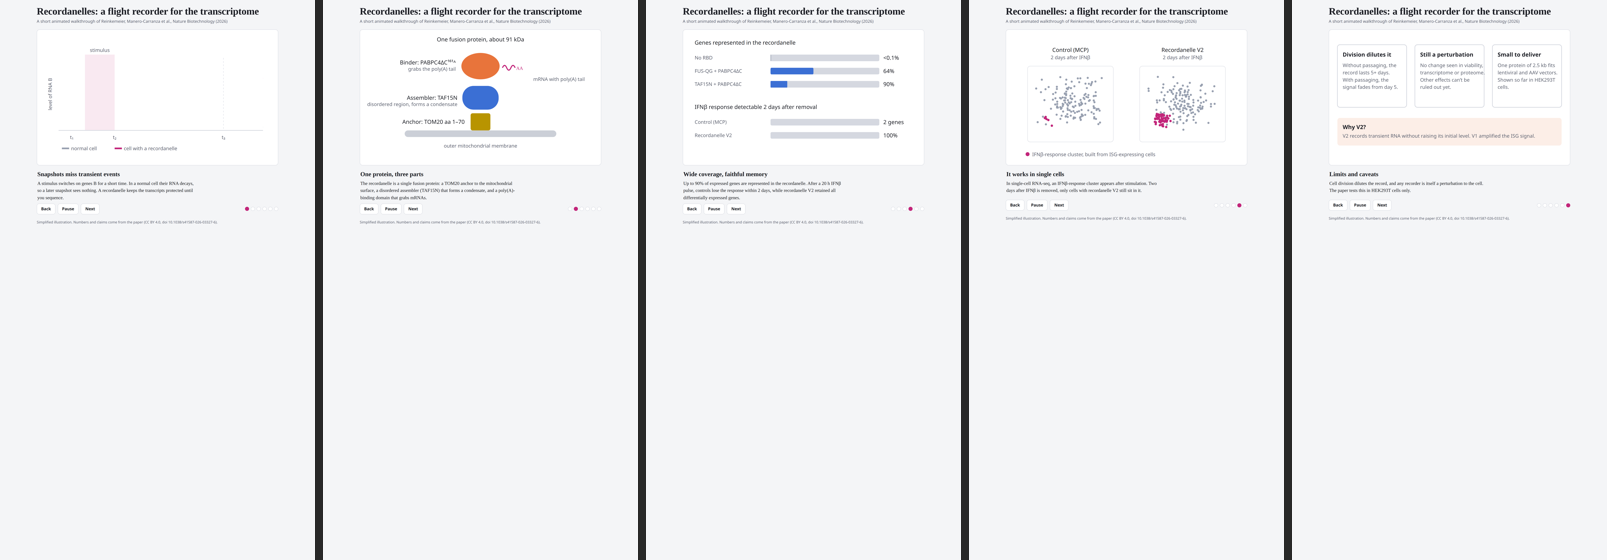


Frame size 2160×3840 px · time mode: virtual
Estimated render time for 1920 frames with 2 workers ≈ 9:36 (min:sec)


In [7]:
#@title 7 · Preview a few frames before the long render { display-mode: "form" }
PREVIEW_AT = "0, 25%, 50%, 75%, 95%"  #@param {type:"string"}
from PIL import Image
from IPython.display import display

ts = []
for tok in PREVIEW_AT.split(","):
    tok = tok.strip()
    if not tok:
        continue
    ts.append(START_S + (float(tok[:-1]) / 100 * DURATION_S if tok.endswith("%") else float(tok)))
cfg = write_cfg()
r = subprocess.run([sys.executable, "render.py", CFG_PATH, "--preview", ",".join(f"{t:.3f}" for t in ts)],
                   capture_output=True, text=True, cwd=os.getcwd())
line = [l for l in r.stdout.splitlines() if l.startswith("PREVIEW_JSON ")]
if r.returncode or not line:
    print(r.stdout[-3000:], r.stderr[-3000:])
    raise SystemExit("Preview failed – see messages above.")
info = json.loads(line[0][len("PREVIEW_JSON "):])
print("\n".join(l for l in r.stdout.splitlines() if l.startswith("[render]")))
ims = [Image.open(f) for f in info["files"]]
h = 560
th = [im.resize((max(1, int(im.width * h / im.height)), h)) for im in ims]
canvas = Image.new("RGB", (sum(t.width for t in th) + 8 * (len(th) - 1), h), (40, 40, 40))
x = 0
for t in th:
    canvas.paste(t, (x, 0)); x += t.width + 8
display(canvas)
total = int(round(DURATION_S * FPS))
est = total * (info["avg_shot_s"] + SETTLE_MS / 1000 + 0.02) / max(1, WORKERS)
print(f"\nFrame size {ims[0].width}×{ims[0].height} px · time mode: {info['mode']}")
print(f"Estimated render time for {total} frames with {WORKERS} workers ≈ {mmss(est)} (min:sec)")

In [8]:
#@title 8 · Render all frames (the slow step – safe to re-run, it resumes) { display-mode: "form" }
cfg = write_cfg()
TOTAL = int(round(DURATION_S * FPS))

def site_fingerprint():
    h = hashlib.sha1()
    if PAGE_URL.startswith("file:"):
        for p in sorted(glob.glob(PROJ + "/**/*", recursive=True)):
            if os.path.isfile(p):
                st = os.stat(p)
                h.update(f"{p}{st.st_size}{int(st.st_mtime)}".encode())
    else:
        h.update(PAGE_URL.encode())
    return h.hexdigest()

sig = hashlib.sha1((json.dumps({k: v for k, v in cfg.items() if k not in ("workers", "resume", "preview_dir")}, sort_keys=True)
                    + site_fingerprint()).encode()).hexdigest()
sig_file = os.path.join(FRAMES, ".sig")
if os.path.exists(sig_file) and open(sig_file).read() != sig:
    print("Settings or page changed since the last run → clearing old frames.")
    shutil.rmtree(FRAMES, ignore_errors=True)
os.makedirs(FRAMES, exist_ok=True)
open(sig_file, "w").write(sig)

per = OW * OH * (0.45 if FRAME_FORMAT == "png" else 0.12)
free = shutil.disk_usage(WORK).free
print(f"Disk: ~{per * TOTAL / 1e9:.1f} GB of frames needed, {free / 1e9:.0f} GB free.")
if per * TOTAL > 0.85 * free:
    print("⚠ Might not fit! Use FRAME_FORMAT = jpeg, a lower OUTPUT_SCALE, or a shorter duration.")

t0 = time.time()
stream([sys.executable, "render.py", CFG_PATH])
print(f"\n✔ Frames rendered in {mmss(time.time() - t0)}")

Disk: ~7.2 GB of frames needed, 92 GB free.
[render] time mode: virtual · 1920 frames · 2 worker(s) · 2160×3840 px
[render] frames 1/1920 (0%) · 0.3 fps · ETA 96:29
[render] frames 7/1920 (0%) · 1.2 fps · ETA 27:36
[render] frames 11/1920 (1%) · 1.3 fps · ETA 24:00
[render] frames 15/1920 (1%) · 1.5 fps · ETA 21:49
[render] frames 21/1920 (1%) · 1.6 fps · ETA 19:59
[render] frames 27/1920 (1%) · 1.7 fps · ETA 18:59
[render] frames 33/1920 (2%) · 1.8 fps · ETA 17:55
[render] frames 41/1920 (2%) · 1.9 fps · ETA 16:16
[render] frames 49/1920 (3%) · 2.1 fps · ETA 15:08
[render] frames 57/1920 (3%) · 2.2 fps · ETA 14:20
[render] frames 63/1920 (3%) · 2.2 fps · ETA 13:55
[render] frames 69/1920 (4%) · 2.2 fps · ETA 14:00
[render] frames 73/1920 (4%) · 2.2 fps · ETA 14:06
[render] frames 77/1920 (4%) · 2.2 fps · ETA 14:11
[render] frames 83/1920 (4%) · 2.2 fps · ETA 13:57
[render] frames 89/1920 (5%) · 2.2 fps · ETA 13:39
[render] frames 93/1920 (5%) · 2.2 fps · ETA 13:45
[render] frames 97/1

In [9]:
#@title 9 · Encode the final MP4 (video + sound + captions) { display-mode: "form" }
ext = "jpg" if FRAME_FORMAT == "jpeg" else "png"
TOTAL = int(round(DURATION_S * FPS))
D = TOTAL / FPS
have = len(glob.glob(f"{FRAMES}/*.{ext}"))
if have < TOTAL:
    raise SystemExit(f"Only {have}/{TOTAL} frames found – run step 8 first.")
os.makedirs(OUT, exist_ok=True)
MASTER = f"{OUT}/{SLUG}_{OW}x{OH}_{FPS}fps.mp4"
COPY1080 = f"{OUT}/{SLUG}_1080p_for_IG_FB.mp4"
COVER = f"{OUT}/{SLUG}_cover.jpg"

ff_filters = subprocess.run(["ffmpeg", "-hide_banner", "-filters"], capture_output=True, text=True).stdout
def hex0x(c):
    c = c.strip().lstrip("#")
    return "0x" + (c if len(c) == 6 else "000000")

# ---------------- video filter graph
burn = CAPTIONS == "burn_in" and SRT_PATH and os.path.exists(SRT_PATH)
if CAPTIONS == "burn_in" and not burn:
    print("ℹ No captions available (needs a TTS script or an uploaded .srt) → continuing without burned-in captions.")
if burn and " subtitles " not in ff_filters:
    print("⚠ This ffmpeg has no 'subtitles' filter → exporting .srt only.")
    burn = False
vf = (f"[0:v]scale={OW}:{OH}:force_original_aspect_ratio=decrease:flags=lanczos,"
      f"pad={OW}:{OH}:(ow-iw)/2:(oh-ih)/2:color={hex0x(BG_COLOR)}")
if burn:
    k = min(OW, OH) / 1080
    CAP = f"{WORK}/captions_burn.srt"
    shutil.copy(SRT_PATH, CAP)
    style = (f"FontName={CAPTION_FONT},FontSize={round(CAPTION_FONT_SIZE * k)},Bold=1,PrimaryColour=&H00FFFFFF&,"
             f"OutlineColour=&H00000000&,BackColour=&H00000000&,BorderStyle=1,Outline={max(1, round(4 * k))},Shadow=0,"
             f"Alignment=2,MarginV={round(CAPTION_BOTTOM_MARGIN * k)},MarginL={round(90 * k)},MarginR={round(90 * k)}")
    vf += f",subtitles=filename={CAP}:original_size={OW}x{OH}:force_style='{style}'"
vf += ",scale=out_color_matrix=bt709:out_range=tv,format=yuv420p[v]"

# ---------------- audio graph
ins, fc, mix, n = [], [], [], 1          # input 0 is the frame sequence
def add_input(path, loop=False):
    global n
    if loop:
        ins.extend(["-stream_loop", "-1"])
    ins.extend(["-i", path])
    n += 1
    return n - 1

STEREO = "aresample=48000,aformat=channel_layouts=stereo"
if NARR_PATH:
    k = add_input(NARR_PATH)
    fc.append(f"[{k}:a]{STEREO},volume={NARRATION_VOLUME_DB}dB[narr]")
if MUSIC_PATH:
    k = add_input(MUSIC_PATH, loop=True)
    chain = (f"[{k}:a]{STEREO},atrim=0:{D:.3f},asetpts=PTS-STARTPTS,volume={MUSIC_VOLUME_DB}dB,"
             f"afade=t=in:st=0:d={MUSIC_FADE_IN_S}")
    if MUSIC_FADE_OUT_S > 0:
        chain += f",afade=t=out:st={max(0, D - MUSIC_FADE_OUT_S):.3f}:d={MUSIC_FADE_OUT_S}"
    if NARR_PATH and DUCK_MUSIC:
        fc += ["[narr]asplit=2[narr_mix][narr_sc]", chain + "[mus0]",
               "[mus0][narr_sc]sidechaincompress=threshold=0.02:ratio=8:attack=20:release=500[mus]"]
        mix += ["[narr_mix]", "[mus]"]
    else:
        fc.append(chain + "[mus]")
        mix += (["[narr]"] if NARR_PATH else []) + ["[mus]"]
elif NARR_PATH:
    mix.append("[narr]")
for j, (p, t, db) in enumerate(SFX_RESOLVED):
    k = add_input(p)
    fc.append(f"[{k}:a]{STEREO},adelay={int(t * 1000)}:all=1,volume={db}dB[sfx{j}]")
    mix.append(f"[sfx{j}]")

has_audio = True
if not mix:
    if SILENT_TRACK_IF_NO_AUDIO:
        ins += ["-f", "lavfi", "-t", f"{D:.3f}", "-i", "anullsrc=r=48000:cl=stereo"]
        fc.append(f"[{n}:a]anull[mx]")
        n += 1
    else:
        has_audio = False
else:
    fc.append(("".join(mix) + f"amix=inputs={len(mix)}:duration=longest:normalize=0:dropout_transition=0[mx]") if len(mix) > 1 else f"{mix[0]}anull[mx]")
if has_audio:
    tail = (f"loudnorm=I={TARGET_LUFS}:TP=-1.5:LRA=11,aresample=48000," if NORMALIZE_LOUDNESS and mix else "")
    fc.append(f"[mx]{tail}apad=whole_dur={D:.3f},atrim=0:{D:.3f},afade=t=out:st={max(0, D - 0.25):.3f}:d=0.25[a]")

# ---------------- codec
color = ["-color_primaries", "bt709", "-color_trc", "bt709", "-colorspace", "bt709", "-color_range", "tv"]
if CODEC == "h265":
    vcodec = ["-c:v", "libx265", "-preset", ENCODE_PRESET, "-crf", str(CRF + 4), "-tag:v", "hvc1", "-pix_fmt", "yuv420p",
              "-x265-params", "log-level=error"] + color
else:
    vcodec = ["-c:v", "libx264", "-preset", ENCODE_PRESET, "-crf", str(CRF), "-profile:v", "high", "-pix_fmt", "yuv420p",
              "-g", str(FPS * 2), "-bf", "2"] + color
acodec = ["-c:a", "aac", "-b:a", "192k", "-ar", "48000", "-ac", "2"] if has_audio else ["-an"]

cmd = (["ffmpeg", "-y", "-hide_banner", "-loglevel", "error", "-progress", "pipe:1", "-nostats",
        "-framerate", str(FPS), "-start_number", "0", "-i", f"{FRAMES}/%06d.{ext}"] + ins +
       ["-filter_complex", ";".join([vf] + fc), "-map", "[v]"] + (["-map", "[a]"] if has_audio else []) +
       vcodec + acodec + ["-r", str(FPS), "-t", f"{D:.3f}", "-movflags", "+faststart", MASTER])

def run_ffmpeg(cmd, total_frames, label):
    p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    nxt, errs = 10, []
    for line in p.stdout:
        line = line.strip()
        if line.startswith("frame="):
            pct = 100 * int(line.split("=")[1] or 0) / total_frames
            if pct >= nxt:
                print(f"  {label}… {int(pct)}%")
                nxt = int(pct / 10) * 10 + 10
        elif not re.match(r"^(fps|stream_|bitrate|total_size|out_time|dup_frames|drop_frames|speed|progress)", line) and line:
            errs.append(line)
    p.wait()
    if p.returncode:
        print("\n".join(errs[-25:]))
        raise RuntimeError("ffmpeg failed – see messages above")

t0 = time.time()
print(f"Encoding {OW}×{OH} · {CODEC.upper()} CRF {CRF if CODEC == 'h264' else CRF + 4} · {D:.1f}s …")
run_ffmpeg(cmd, TOTAL, "encoding")
print(f"✔ Master: {MASTER}  ({os.path.getsize(MASTER) / 1e6:.1f} MB, {mmss(time.time() - t0)})")

EXTRA = []
if ALSO_EXPORT_1080 and max(OW, OH) > 1920:
    sc = "scale='if(gt(iw,ih),min(1920,iw),min(1080,iw))':-2:flags=lanczos"
    run_ffmpeg(["ffmpeg", "-y", "-hide_banner", "-loglevel", "error", "-progress", "pipe:1", "-nostats", "-i", MASTER, "-vf", sc,
                "-c:v", "libx264", "-preset", "medium", "-crf", "18", "-pix_fmt", "yuv420p", "-profile:v", "high", "-g", str(FPS * 2)] + color +
               (["-c:a", "copy"] if has_audio else ["-an"]) + ["-movflags", "+faststart", COPY1080], TOTAL, "1080p copy")
    EXTRA.append(COPY1080)
    print(f"✔ 1080p copy: {COPY1080}  ({os.path.getsize(COPY1080) / 1e6:.1f} MB)")

subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-ss", str(min(COVER_TIME_S, max(0, D - 0.1))), "-i", MASTER,
                "-frames:v", "1", "-q:v", "2", COVER], check=True)
EXTRA.append(COVER)
if SRT_PATH and os.path.exists(SRT_PATH):
    shutil.copy(SRT_PATH, f"{OUT}/{SLUG}_captions.srt")
    EXTRA.append(f"{OUT}/{SLUG}_captions.srt")
if NARR_PATH:
    shutil.copy(NARR_PATH, f"{OUT}/{SLUG}_narration{os.path.splitext(NARR_PATH)[1]}")
    EXTRA.append(f"{OUT}/{SLUG}_narration{os.path.splitext(NARR_PATH)[1]}")
snap = {k: v for k, v in globals().items() if k.isupper() and isinstance(v, (str, int, float, bool, list, tuple)) and k not in ("HTML_TEXT", "DEMO_HTML")}
json.dump(snap, open(f"{OUT}/{SLUG}_settings.json", "w"), indent=1, default=str)
EXTRA.append(f"{OUT}/{SLUG}_settings.json")

Encoding 2160×3840 · H264 CRF 17 · 64.0s …
  encoding… 10%
  encoding… 20%
  encoding… 30%
  encoding… 40%
  encoding… 50%
  encoding… 60%
  encoding… 70%
  encoding… 80%
  encoding… 90%
  encoding… 100%
✔ Master: /content/reel_out/my_explainer/my_explainer_2160x3840_30fps.mp4  (7.6 MB, 5:56)
  1080p copy… 10%
  1080p copy… 20%
  1080p copy… 30%
  1080p copy… 40%
  1080p copy… 50%
  1080p copy… 60%
  1080p copy… 70%
  1080p copy… 80%
  1080p copy… 90%
  1080p copy… 100%
✔ 1080p copy: /content/reel_out/my_explainer/my_explainer_1080p_for_IG_FB.mp4  (3.9 MB)


In [10]:
#@title 10 · Check the result (specs + inline preview) { display-mode: "form" }
import base64
from fractions import Fraction
from IPython.display import HTML, display

def probe(path):
    r = subprocess.run(["ffprobe", "-v", "error", "-print_format", "json", "-show_format", "-show_streams", path], capture_output=True, text=True)
    return json.loads(r.stdout)

info = probe(MASTER)
v = next(s for s in info["streams"] if s["codec_type"] == "video")
a = next((s for s in info["streams"] if s["codec_type"] == "audio"), None)
fps = float(Fraction(v["avg_frame_rate"]))
dur = float(info["format"]["duration"])
size = os.path.getsize(MASTER) / 1e6
head = open(MASTER, "rb").read(200_000)
checks = [
    (f"Resolution {v['width']}×{v['height']}", v["width"] % 2 == 0 and v["height"] % 2 == 0),
    (f"Video {v['codec_name']} · {v['pix_fmt']} · {fps:.2f} fps", v["pix_fmt"] == "yuv420p"),
    (f"Audio {a['codec_name']} {a['sample_rate']} Hz {a['channels']}ch" if a else "No audio track", a is not None),
    (f"Duration {dur:.1f}s ({mmss(dur)})", True),
    (f"Size {size:.1f} MB · bitrate {int(info['format']['bit_rate']) / 1e6:.1f} Mb/s", True),
    ("Fast-start (moov atom first, plays while uploading)", b"moov" in head),
]
for text, ok in checks:
    print("✔" if ok else "⚠", text)
print("\nNote: Instagram/Facebook re-encode uploads and change limits from time to time → use the 1080p copy for posting; check the app for the current max length.")

pv = f"{OUT}/{SLUG}_preview_small.mp4"
side = 720
vf_pv = f"scale='if(gt(iw,ih),-2,{side // 2})':'if(gt(iw,ih),{side // 2},-2)'" if v["width"] >= v["height"] else f"scale={side // 2}:-2"
subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", MASTER, "-vf", vf_pv, "-c:v", "libx264", "-crf", "30", "-preset", "veryfast",
                "-pix_fmt", "yuv420p", "-c:a", "aac", "-b:a", "96k", pv], check=True)
if os.path.getsize(pv) < 25e6:
    b64 = base64.b64encode(open(pv, "rb").read()).decode()
    w = 300 if v["height"] > v["width"] else 640
    display(HTML(f'<video controls playsinline width="{w}" src="data:video/mp4;base64,{b64}"></video>'))
else:
    print("(preview too large to embed – download the file instead)")
os.remove(pv)

✔ Resolution 2160×3840
✔ Video h264 · yuv420p · 30.00 fps
✔ Audio aac 48000 Hz 2ch
✔ Duration 64.0s (1:04)
✔ Size 7.6 MB · bitrate 0.9 Mb/s
✔ Fast-start (moov atom first, plays while uploading)

Note: Instagram/Facebook re-encode uploads and change limits from time to time → use the 1080p copy for posting; check the app for the current max length.


In [11]:
#@title 11 · Download to your computer (and optionally save to Drive) { display-mode: "form" }
WHAT = "all files (zip)"  #@param ["master mp4","IG/FB 1080p copy","all files (zip)"]

outs = [MASTER] + [p for p in EXTRA if os.path.exists(p)]
print("Files created:")
for p in outs:
    print(f"  {os.path.basename(p):55s} {os.path.getsize(p) / 1e6:8.1f} MB")

if WHAT == "master mp4":
    to_dl = [MASTER]
elif WHAT == "IG/FB 1080p copy":
    to_dl = [COPY1080 if os.path.exists(COPY1080) else MASTER]
else:
    zip_path = shutil.make_archive(f"{BASE}/reel_out/{SLUG}_bundle", "zip", OUT)
    to_dl = [zip_path]

if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    dest = f"/content/drive/MyDrive/{DRIVE_FOLDER}/{SLUG}"
    os.makedirs(dest, exist_ok=True)
    for p in outs:
        shutil.copy(p, dest)
    print("✔ Saved to Drive:", dest)

try:
    from google.colab import files
    for p in to_dl:
        print("⬇ downloading", os.path.basename(p))
        files.download(p)
except ImportError:
    print("Not in Colab – files are in", OUT)

if CLEANUP_FRAMES:
    shutil.rmtree(FRAMES, ignore_errors=True)
    print("🧹 Frames deleted to free disk (turn off CLEANUP_FRAMES to keep them for re-encoding).")

Files created:
  my_explainer_2160x3840_30fps.mp4                             7.6 MB
  my_explainer_1080p_for_IG_FB.mp4                             3.9 MB
  my_explainer_cover.jpg                                       0.2 MB
  my_explainer_captions.srt                                    0.0 MB
  my_explainer_narration.wav                                  12.3 MB
  my_explainer_settings.json                                   0.0 MB
⬇ downloading my_explainer_bundle.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

🧹 Frames deleted to free disk (turn off CLEANUP_FRAMES to keep them for re-encoding).


---
## Making your HTML render‑perfect

**Works automatically (deterministic):** CSS animations & transitions · SVG (SMIL) · Web Animations API · `setTimeout` / `setInterval` · `requestAnimationFrame` (canvas, three.js, D3, GSAP, anime.js…) · `performance.now()` / `Date.now()`.

**Avoid / handle differently**
- `<video>` and `<audio>` elements and Web Audio are not frame‑accurate → add all sound in step 6.
- `Math.random()` without a seed changes from run to run → use a seeded generator.
- Live network data → inline it as a snapshot.
- Layout: design for the **layout size** (e.g. 1080×1920) using `vw`/`vh`/`%`, keep key content out of the top and bottom ~15 % (Reels UI covers it), hide controls with `INJECT_CSS` (e.g. `.ctl,.src{display:none}`) or capture one element with `CAPTURE_SELECTOR` (e.g. `.stage`, it must fit inside the viewport).

**Exact timing contract (optional).** If your page defines `window.seek(ms)`, the renderer calls it for every frame instead of the virtual clock:
```js
window.seek = (ms) => {
  // put the page in the state it should have at `ms` milliseconds, synchronously
  timeline.pause(); timeline.time(ms / 1000);   // e.g. GSAP
};
```

**Syncing narration to scenes.** Give each script line its start time (`9 | text`). If a line is longer than its slot you'll get an overlap warning: shorten it, raise `TTS_RATE` (e.g. `+10%`), or let the next scene start later.

## Troubleshooting

| Symptom | Fix |
|---|---|
| Frames are blank / white | The page failed to load: check the `PAGE_URL`, external files in the zip, or use `SOURCE = "paste"` with a fully self‑contained HTML |
| Animation stuck at the first frame | Set `TIME_MODE = "virtual"`; if you use a custom engine, define `window.seek` |
| Text/elements too small or cut off | The layout size is the CSS viewport. Use a preset that matches your design (or `Custom`), not a bigger `OUTPUT_SCALE` |
| Render too slow | `FRAME_FORMAT = jpeg`, more `WORKERS` (Colab has 2 CPUs; High‑RAM runtimes have more), `OUTPUT_SCALE = 1`, lower `FPS` |
| `edge-tts failed` | It needs internet access to Microsoft's voice service. Check the voice name, or use `NARRATION_SOURCE = "upload"` |
| Narration is longer than the video | `DURATION_MODE = match_audio` or raise `DURATION_S` |
| Burned captions missing | Your ffmpeg lacks libass → captions are exported as `.srt`; upload that to Instagram/Facebook instead |
| Disk full | `FRAME_FORMAT = jpeg`, lower scale, keep `CLEANUP_FRAMES` on |
| Re‑encode without re‑rendering | Turn off `CLEANUP_FRAMES`, change encode settings, run only steps 2, 6 and 9 |

## Posting tips
- Upload the **1080p copy** (`*_1080p_for_IG_FB.mp4`) to Instagram/Facebook; keep the 4K master for YouTube or archives.
- Reels are 9:16 (1080×1920); feed videos work well at 4:5 (1080×1350).
- Use the `*_cover.jpg` as the cover and the `.srt` for Facebook/YouTube captions.
- Only use music you have the rights to; copyrighted tracks can get Reels muted.
- Credit your sources in the caption (the recordanelle paper is CC BY 4.0).